In [54]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import drive
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

drive.mount('/content/gdrive')


Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


# data preprocessing and cleaning

In [22]:
# data cleaning/preperation
df=pd.read_csv('gdrive/My Drive/Colab Notebooks/bern 02 stuff/Challenge project/data.csv')

# drop unneeded columns
df = df.drop(columns=['Unnamed: 32','id'])

# Convert diagnosis column to binary
# 1 for malignant and 0 for benign
df['diagnosis'] = df['diagnosis'].apply(lambda x: 1 if x == 'M' else 0)

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [23]:
df.columns

Index(['diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst'],
      dtype='object')

# descriptive statistics

In [30]:
# class distribution of malignant vs benign

count = df['diagnosis'].value_counts()
percentage = count/len(df) * 100
print(count)
print(percentage)

diagnosis
0    357
1    212
Name: count, dtype: int64
diagnosis
0    62.741652
1    37.258348
Name: count, dtype: float64


In [31]:
# grouped summaries of the variables
df.groupby('diagnosis').mean()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
diagnosis,,,,,,,,,,,,,,,,,,,,,
0,12.146524,17.914762,78.075406,462.790196,0.092478,0.080085,0.046058,0.025717,0.174186,0.062867,...,13.379801,23.515070,87.005938,558.899440,0.124959,0.182673,0.166238,0.074444,0.270246,0.079442
1,17.462830,21.604906,115.365377,978.376415,0.102898,0.145188,0.160775,0.087990,0.192909,0.062680,...,21.134811,29.318208,141.370330,1422.286321,0.144845,0.374824,0.450606,0.182237,0.323468,0.091530


In [32]:
# look at the min/max values
# look at standard deviation
df.describe()

# note that we will need to scale the variables before using a ML model

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,0.372583,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,0.483918,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,0.000000,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,0.000000,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,0.000000,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,1.000000,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,1.000000,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


# visualizations

In [ ]:
# Histograms of mean variables with hue for diagnosis
n_bins = 20

fig, axs = plt.subplots(5, 2, figsize=(15, 20), tight_layout=True)

axs[0,0].hist(df['area_mean'], bins=n_bins)
axs[0,0].set_title('Area Mean')
axs[0,1].hist(df['perimeter_mean'], bins=n_bins)
axs[0,1].set_title('Perimeter Mean')
axs[1,0].hist(df['texture_mean'], bins=n_bins)
axs[1,0].set_title('Texture Mean')
axs[1,1].hist(df['smoothness_mean'], bins=n_bins)
axs[1,1].set_title('Smoothness Mean')
axs[2,0].hist(df['radius_mean'], bins=n_bins)
axs[2,0].set_title('Radius Mean')
axs[2,1].hist(df['compactness_mean'], bins=n_bins)
axs[2,1].set_title('Compactness Mean')
axs[3,0].hist(df['concavity_mean'], bins=n_bins)
axs[3,0].set_title('Concavity Mean')
axs[3,1].hist(df['concave points_mean'], bins=n_bins)
axs[3,1].set_title('Concave Points Mean')
axs[4,0].hist(df['symmetry_mean'], bins=n_bins)
axs[4,0].set_title('Symmetry Mean')
axs[4,1].hist(df['fractal_dimension_mean'], bins=n_bins)
axs[4,1].set_title('Fractal Dimension Mean')

plt.show()

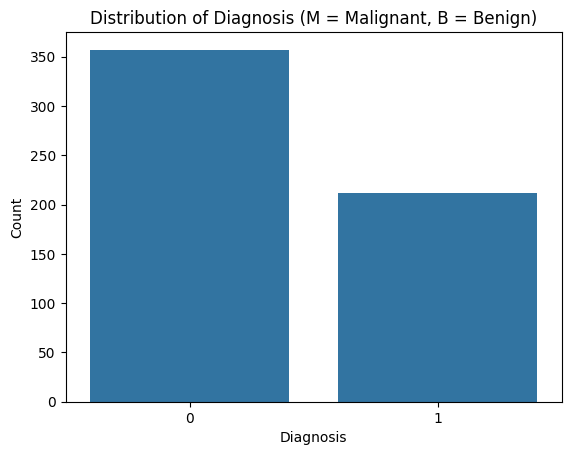

In [41]:
# box plot of malignant vs benign
fig = plt.figure()
ax1 = sns.countplot(data=df, x='diagnosis')
ax1.set_title('Distribution of Diagnosis (M = Malignant, B = Benign)')
ax1.set_xlabel('Diagnosis')
ax1.set_ylabel('Count')
plt.show()

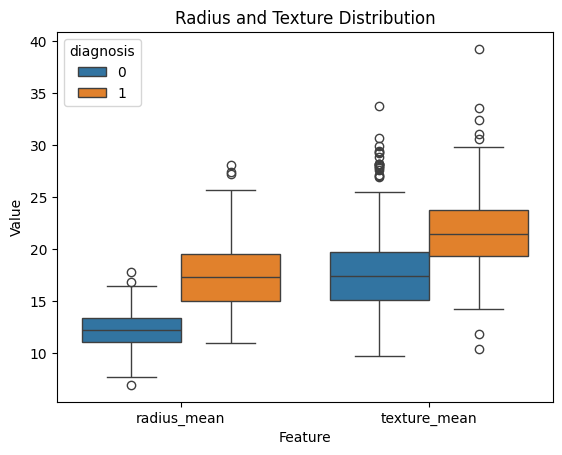

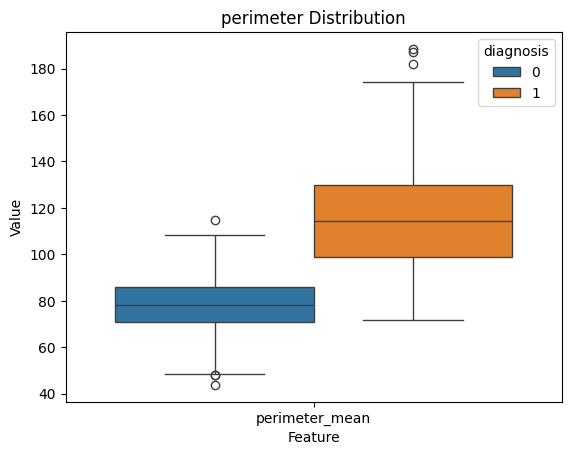

In [48]:
# box plot to compare features

# Melting a few key features for comparison
df_melted = pd.melt(df, id_vars='diagnosis', value_vars=['radius_mean', 'texture_mean'])
box = sns.boxplot(data=df_melted, x='variable', y='value', hue='diagnosis')
box.set_title('Radius and Texture Distribution')
box.set_xlabel('Feature')
box.set_ylabel('Value')
plt.show()


# Melting a few key features for comparison
df_melted = pd.melt(df, id_vars='diagnosis', value_vars=['perimeter_mean'])
box = sns.boxplot(data=df_melted, x='variable', y='value', hue='diagnosis')
box.set_title('perimeter Distribution')
box.set_xlabel('Feature')
box.set_ylabel('Value')
plt.show()

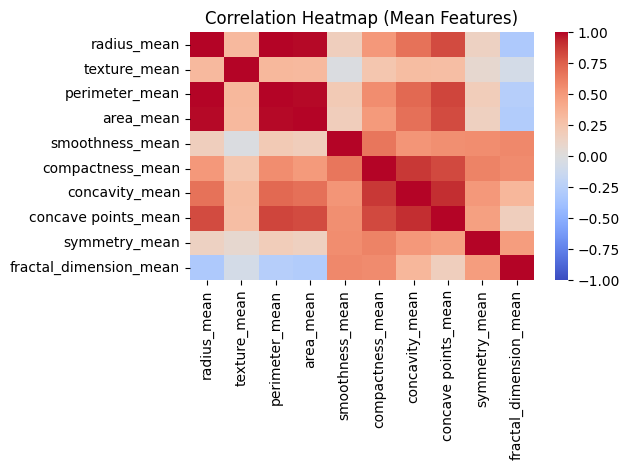

In [49]:
# heat map for correlation

mean_features = [col for col in df.columns if 'mean' in col]
corr_matrix = df[mean_features].corr()
heat = sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
heat.set_title('Correlation Heatmap (Mean Features)')
plt.tight_layout()
plt.show()

# pca analysis

we will do this on raw, centered. standardized data

In [51]:
# standard
df_raw = df.drop(columns=['diagnosis'])

# centered
df_centered = df - df.mean()
df_centered = df.drop(columns=['diagnosis'])

# standardized
df_standardized = (df - df.mean()) / df.std()
df_standardized = df_standardized.drop(columns=['diagnosis'])

In [53]:
# SVD Raw data
U_raw, S_raw, V_raw = np.linalg.svd(df_raw.values, full_matrices=False)
pve_raw = S_raw**2 / np.sum(S_raw**2)

print("Raw Data")
print(f"single value:{S_raw}")
print(f"PVE:{pve_raw}")

# SVD Centered data
U_cen, S_cen, V_cen = np.linalg.svd(df_centered.values, full_matrices=False)
pve_cen = S_cen**2 / np.sum(S_cen**2)

print("Centered Data")
print(f"single value:{S_cen}")
print(f"PVE:{pve_cen}")

# SVD Scaled data
U_std, S_std, V_std = np.linalg.svd(df_standardized, full_matrices=False)
pve_std = S_std**2 / np.sum(S_std**2)

print("Standardized Data")
print(f"single value:{S_std}")
print(f"PVE:{pve_std}")

Raw Data
single value:[3.07864446e+04 2.48044578e+03 8.80462945e+02 5.55123288e+02
 1.53142190e+02 5.72902829e+01 3.22542483e+01 1.45492521e+01
 9.83274331e+00 7.07006116e+00 4.42538572e+00 2.20566405e+00
 1.40917082e+00 1.16924142e+00 8.68094237e-01 6.18637975e-01
 4.74761814e-01 4.61433991e-01 3.28021267e-01 3.07502385e-01
 2.10729014e-01 2.01729800e-01 1.40891440e-01 1.27127383e-01
 9.86006440e-02 8.42592774e-02 5.64713680e-02 4.44629475e-02
 3.37465202e-02 2.07265556e-02]
PVE:[9.92394111e-01 6.44205727e-03 8.11684532e-04 3.22659159e-04
 2.45558408e-05 3.43658458e-06 1.08927855e-06 2.21639133e-07
 1.01231229e-07 5.23373158e-08 2.05053584e-08 5.09382280e-09
 2.07918144e-09 1.43144112e-09 7.89039692e-10 4.00717450e-10
 2.36002534e-10 2.22938087e-10 1.12659834e-10 9.90061289e-11
 4.64958052e-11 4.26093806e-11 2.07842483e-11 1.69216739e-11
 1.01794569e-11 7.43362355e-12 3.33904077e-12 2.06995833e-12
 1.19240311e-12 4.49799921e-13]
Centered Data
single value:[3.07864446e+04 2.48044578e+0

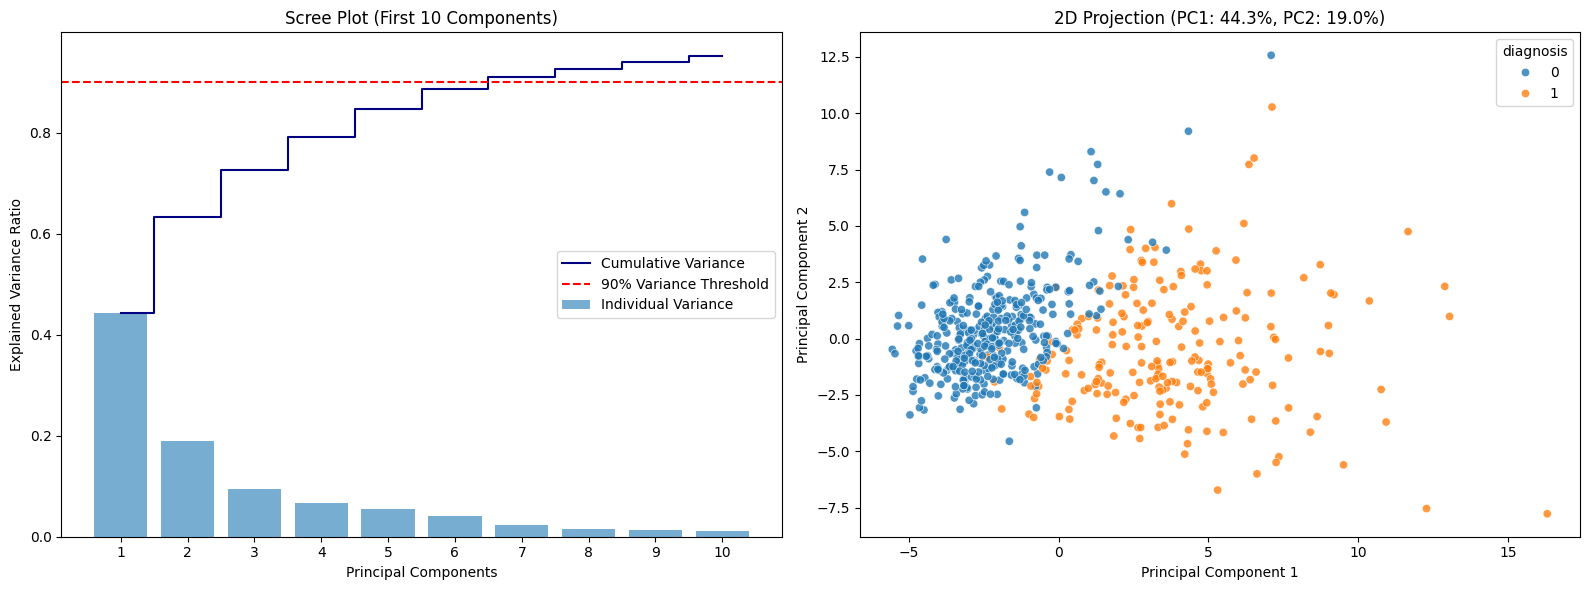

Top 5 Features Contributing to PC1:
concave points_mean     0.260854
concavity_mean          0.258400
concave points_worst    0.250886
compactness_mean        0.239285
perimeter_worst         0.236640
Name: PC1, dtype: float64


In [56]:
X = df.copy()
X = X.drop(columns=['diagnosis'])
y = df['diagnosis']

# Standardize features (mandatory step for PCA)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Perform PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Calculate variance ratios
var_exp = pca.explained_variance_ratio_
cum_var_exp = np.cumsum(var_exp)

# 4. Plot Scree Plot and 2D Scatterplot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Scree Plot
ax1.bar(range(1, 11), var_exp[:10], alpha=0.6, align='center', label='Individual Variance')
ax1.step(range(1, 11), cum_var_exp[:10], where='mid', label='Cumulative Variance', color='navy')
ax1.axhline(y=0.90, color='r', linestyle='--', label='90% Variance Threshold')
ax1.set_xlabel('Principal Components')
ax1.set_ylabel('Explained Variance Ratio')
ax1.set_xticks(range(1, 11))
ax1.set_title('Scree Plot (First 10 Components)')
ax1.legend(loc='best')

# 2D PCA Scatter Plot
pca_df = pd.DataFrame(data=X_pca[:, :2], columns=['PC1', 'PC2'])
pca_df['diagnosis'] = y.values
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='diagnosis',
                palette=['#1f77b4', '#ff7f0e'], alpha=0.8, ax=ax2)
ax2.set_title(f'2D Projection (PC1: {var_exp[0]*100:.1f}%, PC2: {var_exp[1]*100:.1f}%)')
ax2.set_xlabel('Principal Component 1')
ax2.set_ylabel('Principal Component 2')

plt.tight_layout()
plt.show()

# Extract Feature Loadings for PC1
loadings = pd.DataFrame(pca.components_.T, columns=[f'PC{i+1}' for i in range(X.shape[1])], index=X.columns)
print("Top 5 Features Contributing to PC1:")
print(loadings['PC1'].abs().sort_values(ascending=False).head(5))